Accuracy : 0.85
Precision: 0.7777777777777778
Recall   : 0.8
F1-Score : 0.7887323943661971
[[57  8]
 [ 7 28]]
education_num     0.618386
hours_per_week    0.196456
marital_Single    0.172692
age               0.012466
sex_Male          0.000000
dtype: float64


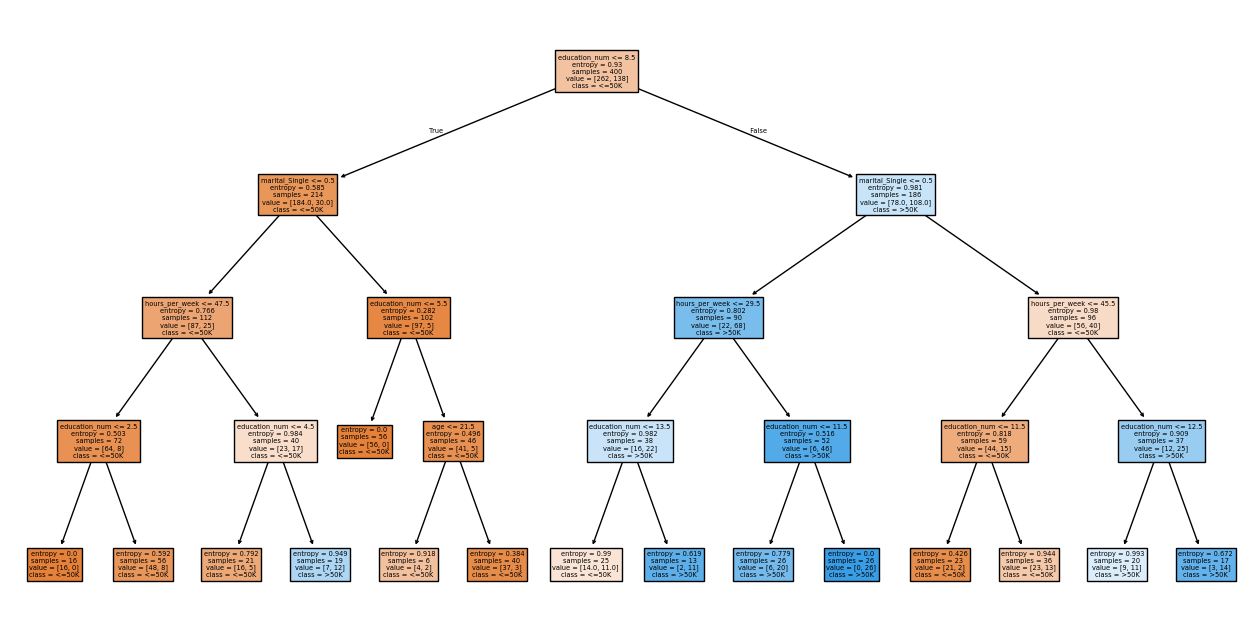

In [1]:
#Dataset hint: for Experiments 3, 4 and 5, make age, education_num and hours_per_week as random numbers, and sex and marital as random categories. Build income (>50K / <=50K) from a score that rises with education, hours and being married, plus noise.
# Decision Tree: splits data using entropy; max_depth limits tree size to avoid overfitting. Feature importance shows key factors.
import numpy as np, pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix

np.random.seed(1)
n = 500
df = pd.DataFrame({"age": np.random.randint(18, 70, n),
                   "education_num": np.random.randint(1, 16, n),
                   "hours_per_week": np.random.randint(10, 70, n),
                   "sex": np.random.choice(["Male", "Female"], n),
                   "marital": np.random.choice(["Married", "Single"], n)})
score = df.education_num*0.4 + df.hours_per_week*0.05 + (df.marital == "Married")*2 + np.random.normal(0, 1.5, n)
df["income"] = np.where(score > score.median() + 1, ">50K", "<=50K")

X = pd.get_dummies(df.drop("income", axis=1), drop_first=True)
y = df["income"].map({"<=50K": 0, ">50K": 1})
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=1, stratify=y)

model = DecisionTreeClassifier(criterion="entropy", max_depth=4, random_state=1)
model.fit(X_train, y_train)
pred = model.predict(X_test)

print("Accuracy :", accuracy_score(y_test, pred))
print("Precision:", precision_score(y_test, pred))
print("Recall   :", recall_score(y_test, pred))
print("F1-Score :", f1_score(y_test, pred))
print(confusion_matrix(y_test, pred))
print(pd.Series(model.feature_importances_, index=X.columns).sort_values(ascending=False))

plt.figure(figsize=(16, 8))
plot_tree(model, feature_names=list(X.columns), class_names=["<=50K", ">50K"], filled=True)
plt.show()